# DBO 10-m wind — speed change and directional change, on the scorecard's estimator

Self-contained: it will use the cached monthly u/v stack if it exists and
stream + build it from MERRA-2 if it does not.

### Why this notebook exists

The published wind trend map was an **annual**-mean Theil-Sen fit, while the DBO scorecard's wind row
is a **monthly month-of-year anomaly** fit. Those answer different questions, and only chl, b$_{bp}$
and a$_{dg}$ were ever reconciled onto the common estimator (`2_figures/fig02_trend-maps-chl-bbp-adg.ipynb`).
This notebook puts wind on it as well, and splits the one old figure into the two physically distinct
claims it was conflating:

| | figure | quantity |
|---|---|---|
| 1 | **speed change** | Theil-Sen on the monthly speed anomaly, m s⁻¹ decade⁻¹, per pixel and per box |
| 2 | **directional change** | trends in the zonal (u) and meridional (v) anomalies, plus the rotation of the mean wind vector between the first and last decade |

Both use Theil-Sen with an AR(1)-adjusted Mann-Kendall p, identical to the chl / b$_{bp}$ / a$_{dg}$
maps and to the scorecard, so a significant box here means the same thing it means there.

### The caveat that does not go away

`M2TMNXSLV` provides **monthly-mean components**, so speed here is √(ū² + v̄²) — the magnitude of the
mean vector, not the mean of the instantaneous speeds. Since √(ū²+v̄²) ≤ mean(√(u²+v²)), within-month
direction changes cancel and this quantity is biased low. A downward trend therefore means *either*
weaker wind *or* less directionally steady wind, and no reprocessing of monthly means can separate
them — that needs sub-monthly data. Figure 2 is the partial remedy: if speed falls while the
components carry significant trends and the mean vector rotates, the "less steady" reading is in
play; if the components are flat while speed falls, it is closer to a true weakening.

### Memory

The monthly stack is ~1.5 GB. Materialising u, v **and** speed as full `(557, 845, 906)` float32
arrays is ~5 GB and will thrash. Section 5 therefore makes a **single pass**, one month at a time,
and keeps only: a strided cube for the per-pixel fits, full-resolution box means, and the two decadal
mean vectors. Peak memory is a few hundred MB. The box means are **not** strided, so the numbers you
compare against the scorecard are at full resolution.

## 1. Imports

In [5]:
import time as _time, warnings, gc
from pathlib import Path
from datetime import date

import numpy as np, pandas as pd, xarray as xr
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.path import Path as MplPath
import cartopy.crs as ccrs, cartopy.feature as cfeature
from scipy.stats import theilslopes, kendalltau, norm
warnings.filterwarnings("ignore")

try:
    import earthaccess
    from pyresample import AreaDefinition, geometry
    from pyresample.kd_tree import resample_gauss, resample_nearest
    HAVE_STREAM = True
except ImportError as e:
    from pyresample import AreaDefinition
    HAVE_STREAM = False
    print(f"streaming deps missing ({e}) — the cached stack must already exist")

try:
    import cmocean; DIVCMAP = cmocean.cm.balance
except ImportError:
    DIVCMAP = plt.get_cmap("RdBu_r")

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "figure.facecolor": "white",
    "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Helvetica Neue", "Arial", "Nimbus Sans", "DejaVu Sans"],
    "axes.linewidth": 0.9, "axes.edgecolor": "0.2",
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
})
print("imports OK")

imports OK


## 2. Configuration

Grid, boxes and projections are copied verbatim from the other DBO notebooks, so these pixels are the
same pixels. `STRIDE` controls only the **map** fits — box means are always full resolution.

In [6]:
WIND_SHORT = "M2TMNXSLV"          # MERRA-2 monthly time-averaged single-level diagnostics
UVAR, VVAR = "U10M", "V10M"       # 10-m eastward / northward wind (m/s)
START_DATE = date(1980, 1, 1)     # MERRA-2 record start
END_DATE   = date.today()
DBO_BBOX   = (-180.0, 50.0, -124.0, 74.0)
RESAMPLE, ROI = "gauss", 60_000   # radius of influence (m); MERRA-2 cells ~30-55 km

STRIDE     = 5      # per-pixel fits on every STRIDE-th pixel (4 km -> 20 km), painted over the block
MIN_MONTHS = 60     # monthly anomalies required before a pixel is trended
MIN_YEARS  = 15     # ... and they must span at least this many years
SIG        = 0.05   # significance threshold for hatching and for box outlines

dbo_area = AreaDefinition(
    area_id="ease2_north_dbo_4km",
    description="EASE-Grid 2.0 North subset: Aleutians -> Beaufort (DBO1-8), 4 km",
    proj_id="EPSG:6931",
    projection={"proj": "laea", "lat_0": 90, "lon_0": 0, "x_0": 0, "y_0": 0,
                "datum": "WGS84", "units": "m"},
    width=906, height=845, area_extent=(-3_624_000, 992_000, 0, 4_372_000))
ny, nx = dbo_area.shape
xs, ys = dbo_area.get_proj_vectors()
lons2d, lats2d = dbo_area.get_lonlats()
x0, y0, x1, y1 = dbo_area.area_extent
data_crs = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=0)
disp     = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=-152)
MAP_EXTENT = [-180, -124, 49, 73.5]

DBO_BOXES = {
    "DBO1": [(63.769462,-172.312422),(61.945988,-172.186927),(61.846516,-175.790978),(63.662718,-176.147111)],
    "DBO2": [(65.107747,-170.865176),(65.097001,-167.859549),(64.481828,-167.907758),(64.493658,-170.840669)],
    "DBO3": [(66.785880,-171.330008),(68.608869,-171.419334),(68.572412,-166.481029),(66.752281,-166.755808)],
    "DBO4": [(71.994000,-164.226000),(71.801000,-159.729000),(70.641000,-160.305000),(70.821000,-164.556000)],
    "DBO5": [(71.807730,-158.537691),(71.635583,-155.931220),(71.110941,-156.307277),(71.278277,-158.847920)],
    "DBO6": [(71.850000,-150.108000),(70.890000,-150.976000),(71.159000,-153.865000),(72.119000,-152.980000)],
    "DBO7": [(70.868000,-141.528000),(69.946000,-142.679000),(70.333000,-145.439000),(71.253000,-144.256000)],
    "DBO8": [(70.834000,-125.155000),(70.049000,-126.997000),(70.664000,-129.354000),(71.442000,-127.431000)],
}

OUT_DIR = Path.cwd() / "outputs_wind"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# figure type scale — matches 2_figures/fig03_4a_6_S3_S4_re-do-figs.ipynb
FS_TITLE, FS_CB_LABEL, FS_CB_TICK, FS_BOX = 21, 19, 16, 15
SIG_BOX_COLOR, SIG_BOX_LW = "#ffd400", 4.0     # gold + thick == this box's trend is significant
NS_BOX_COLOR,  NS_BOX_LW  = "white", 1.4

print(f"{WIND_SHORT} | {START_DATE} -> {END_DATE} | grid {dbo_area.shape} | "
      f"stride {STRIDE} ({4*STRIDE} km fits) | out -> {OUT_DIR}")

M2TMNXSLV | 1980-01-01 -> 2026-08-26 | grid (845, 906) | stride 5 (20 km fits) | out -> ~/outputs_wind


## 3. Locate or build the monthly u/v stack

Looks for `monthly_uv10_ease2_gauss.nc` in the usual places. If it is missing, authenticates to
Earthdata and builds it: for each month, stream only the DBO subset of `U10M`/`V10M`, regrid onto the
EASE-2 grid with a Gaussian resample, and write the result once.

**MERRA-2 is served by GES DISC.** If the search or the stream returns 401/403, log in at
`urs.earthdata.nasa.gov` → Applications → Authorized Apps and authorize *NASA GESDISC DATA ARCHIVE*.

In [7]:
UV_CACHE = None          # set to a path string to point at the stack explicitly

# ADD_YOUR_PATH is searched first, then the home directory, the working folder and its parent.
_CANDS = [Path("ADD_YOUR_PATH"), Path.home(), Path.cwd(), Path.cwd().parent,  # add your path
          Path.home() / "ADD_YOUR_PATH"]  # add your path
_SUBS  = ["", "outputs_wind", "wind", "wind/outputs_wind", "ADD_YOUR_PATH/wind/outputs_wind"]

def _find_uv():
    tried = []
    for b in _CANDS:
        for s in _SUBS:
            root = b / s if s else b
            tried.append(root)
            if not root.exists(): continue
            hits = sorted(root.glob("monthly_uv10_ease2_*.nc"))
            if hits: return hits[-1], tried
    return None, tried

if UV_CACHE:
    p_uv, _tried = Path(UV_CACHE), []
    if not p_uv.exists():
        raise FileNotFoundError(f"UV_CACHE points at {p_uv}, which does not exist")
else:
    p_uv, _tried = _find_uv()
    if p_uv is None:
        print("monthly_uv10_ease2_*.nc not found. Searched:")
        for r in dict.fromkeys(_tried):
            print(f"   {'exists' if r.exists() else '  --  '}  {r}")

if p_uv is None:
    if not HAVE_STREAM:
        raise RuntimeError("no cached stack and earthaccess/pyresample unavailable — cannot build")
    print("no cached stack found — streaming MERRA-2 (this is the slow path, ~1 granule/month)")
    auth = earthaccess.login(persist=True)

    def _search(sn, tspan, **kw):
        for k in range(5):
            try: return earthaccess.search_data(short_name=sn, temporal=tspan, **kw)
            except Exception: _time.sleep(2 * (k + 1))
        raise RuntimeError(f"CMR search failed for {sn}")

    grans = _search(WIND_SHORT, (START_DATE.isoformat(), END_DATE.isoformat()))
    print(f"  {len(grans)} monthly granules in window")

    def _bbox_sel(da, bbox, latn, lonn, pad=0.0):
        lon0, lat0, lon1, lat1 = bbox; la, lo = da[latn].values, da[lonn].values
        ls = slice(lat1+pad, lat0-pad) if la[0] > la[-1] else slice(lat0-pad, lat1+pad)
        xx = slice(lon0-pad, lon1+pad) if lo[0] < lo[-1] else slice(lon1+pad, lon0-pad)
        return da.sel({latn: ls, lonn: xx})

    def _regrid(vals, lon2d, lat2d):
        ok = np.isfinite(vals)
        if ok.sum() == 0: return np.full(dbo_area.shape, np.nan, np.float32)
        sw = geometry.SwathDefinition(lons=lon2d[ok], lats=lat2d[ok])
        out = (resample_gauss(sw, vals[ok], dbo_area, radius_of_influence=ROI, sigmas=ROI/2,
                              neighbours=8, fill_value=np.nan, reduce_data=False)
               if RESAMPLE == "gauss" else
               resample_nearest(sw, vals[ok], dbo_area, radius_of_influence=ROI,
                                fill_value=np.nan, reduce_data=False))
        return out.astype(np.float32)

    U_ = np.full((len(grans), ny, nx), np.nan, np.float32)
    V_ = np.full((len(grans), ny, nx), np.nan, np.float32)
    times, keep, lon2d, lat2d = [], 0, None, None
    t0 = _time.time()
    for k, g in enumerate(grans):
        try:
            f = earthaccess.open([g], show_progress=False)[0]
            with xr.open_dataset(f, engine="h5netcdf") as ds:
                sub = _bbox_sel(ds[[UVAR, VVAR]], DBO_BBOX, "lat", "lon").squeeze()
                uu = sub[UVAR].values.astype(np.float32)
                vv = sub[VVAR].values.astype(np.float32)
                tt = pd.to_datetime(np.atleast_1d(ds["time"].values)[0])
            try: f.close()
            except Exception: pass
        except Exception as e:
            print(f"    skip granule ({e})"); continue
        if lon2d is None:
            lon2d, lat2d = np.meshgrid(sub["lon"].values, sub["lat"].values)
        U_[keep] = _regrid(uu, lon2d, lat2d); V_[keep] = _regrid(vv, lon2d, lat2d)
        times.append(tt); keep += 1
        if k % 50 == 0:
            gc.collect(); print(f"  {k}/{len(grans)}  ({_time.time()-t0:.0f}s)", end="\r")
    p_uv = OUT_DIR / f"monthly_uv10_ease2_{RESAMPLE}.nc"
    xr.Dataset({"u": (("time","y","x"), U_[:keep]), "v": (("time","y","x"), V_[:keep])},
               coords={"time": times, "y": ys, "x": xs},
               attrs={"product": WIND_SHORT, "vars": f"{UVAR},{VVAR}", "resample": RESAMPLE,
                      "grid": "EASE-Grid 2.0 North (EPSG:6931) 4 km"}
               ).to_netcdf(p_uv, encoding={v: {"zlib": True, "complevel": 4} for v in ("u","v")})
    del U_, V_; gc.collect()
    print(f"\nbuilt + cached {keep} months -> {p_uv}")

print(f"stack: {p_uv}")

stack: ~/monthly_uv10_ease2_gauss.nc


## 4. DBO box masks on the EASE-2 grid

In [8]:
grid_pts = np.column_stack([lons2d.ravel(), lats2d.ravel()])
box_masks = {name: MplPath([(lo, la) for la, lo in corners] + [(corners[0][1], corners[0][0])])
                        .contains_points(grid_pts).reshape(lons2d.shape)
             for name, corners in DBO_BOXES.items()}
for name, m in box_masks.items():
    print(f"  {name}: {int(m.sum()):>6,} grid cells")

  DBO1:  2,412 grid cells
  DBO2:    605 grid cells
  DBO3:  2,561 grid cells
  DBO4:  1,293 grid cells
  DBO5:    351 grid cells
  DBO6:    739 grid cells
  DBO7:    773 grid cells
  DBO8:    760 grid cells


## 5. One streaming pass over the stack

One month at a time. Produces only what the two figures need:

| product | used by | size |
|---|---|---|
| `SUB["u"/"v"/"spd"]` — every `STRIDE`-th pixel | per-pixel trend maps | ~70 MB each |
| `BOXSER` — **full-resolution** box means | box trends / scorecard comparison | negligible |
| `u0,v0,u1,v1` — first- and last-decade mean vectors | the rotation panel | 4 × 3 MB |

In [9]:
_uv = xr.open_dataset(p_uv)
_uv = _uv.assign_coords(time=pd.to_datetime(_uv.time.values).to_period("M").to_timestamp())
assert (_uv.sizes["y"], _uv.sizes["x"]) == dbo_area.shape, f"uv grid != {dbo_area.shape}"

WT    = pd.to_datetime(_uv.time.values)
MOY   = WT.month.values
DECYR = (WT.year + (WT.month - 0.5) / 12.0).values.astype(float)
NT, S = len(WT), STRIDE
_ys = ny // S + (ny % S > 0); _xs = nx // S + (nx % S > 0)

SUB    = {k: np.full((NT, _ys, _xs), np.nan, np.float32) for k in ("u", "v", "spd")}
BOXSER = {k: {n: np.full(NT, np.nan) for n in box_masks} for k in ("u", "v", "spd")}
_D0 = (WT.year >= WT.year.min()) & (WT.year < WT.year.min() + 10)     # first decade
_D1 = (WT.year > WT.year.max() - 10) & (WT.year <= WT.year.max())     # last decade
_acc = {k: np.zeros((ny, nx), np.float64) for k in ("u0", "v0", "u1", "v1")}
_n0 = _n1 = 0

# Read in BLOCKS, not one month at a time. The file is zlib-compressed, so a single-month
# .isel().values forces a whole chunk to be decompressed and thrown away; blocking amortises
# that over BLOCK months and cut this pass from ~1.4 s/month to a fraction of it.
# Flat box indices are precomputed too — 24 boolean fancy-indexes per month over 765k cells adds up.
BLOCK = 24
_bidx = {n: np.flatnonzero(m.ravel()) for n, m in box_masks.items()}

t0 = _time.time()
for b0 in range(0, NT, BLOCK):
    b1 = min(b0 + BLOCK, NT)
    ub = _uv["u"].isel(time=slice(b0, b1)).values.astype(np.float32)
    vb = _uv["v"].isel(time=slice(b0, b1)).values.astype(np.float32)
    sb = np.sqrt(ub * ub + vb * vb, dtype=np.float32)      # magnitude of the MONTHLY-MEAN vector
    for k, ab in (("u", ub), ("v", vb), ("spd", sb)):
        SUB[k][b0:b1] = ab[:, ::S, ::S]
        flat = ab.reshape(b1 - b0, -1)
        for n, ix in _bidx.items():
            BOXSER[k][n][b0:b1] = np.nanmean(flat[:, ix], axis=1)
    m0 = _D0[b0:b1]; m1 = _D1[b0:b1]
    if m0.any():
        _acc["u0"] += np.nan_to_num(ub[m0]).sum(0); _acc["v0"] += np.nan_to_num(vb[m0]).sum(0)
        _n0 += int(m0.sum())
    if m1.any():
        _acc["u1"] += np.nan_to_num(ub[m1]).sum(0); _acc["v1"] += np.nan_to_num(vb[m1]).sum(0)
        _n1 += int(m1.sum())
    del ub, vb, sb
    print(f"   {b1}/{NT} months  ({_time.time()-t0:.0f}s)", end="\r")

u0, v0 = (_acc["u0"]/_n0).astype(np.float32), (_acc["v0"]/_n0).astype(np.float32)
u1, v1 = (_acc["u1"]/_n1).astype(np.float32), (_acc["v1"]/_n1).astype(np.float32)
_uv.close(); del _acc; gc.collect()
print(f"streamed {NT} months ({WT[0]:%Y-%m} -> {WT[-1]:%Y-%m}) in {_time.time()-t0:.0f}s | "
      f"strided cube {SUB['u'].shape} = {SUB['u'].nbytes/1e6:.0f} MB each | "
      f"decade means: {_n0} vs {_n1} months")

streamed 557 months (1980-01 -> 2026-05) in 71s | strided cube (557, 169, 182) = 69 MB each | decade means: 120 vs 113 months


## 6. Trend helpers and map furniture

Theil-Sen slope with an AR(1)-adjusted Mann-Kendall p — the same estimator as the DBO scorecard and
the chl / b$_{bp}$ / a$_{dg}$ maps. Reported in **absolute units per decade**, because that is what
the scorecard's wind row reports; a percentage of a mean speed is a different quantity.

In [10]:
def _lag1(x):
    x = np.asarray(x, float); a, b = x[1:], x[:-1]
    v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 5 else 0.0

def mk_ar1(x, y, minn=MIN_MONTHS):
    x = np.asarray(x, float); y = np.asarray(y, float)
    v = np.isfinite(x) & np.isfinite(y); x, y = x[v], y[v]; n = len(x)
    if n < minn:
        return dict(slope=np.nan, per_dec=np.nan, p_adj=np.nan, n=n)
    slope, intercept, _, _ = theilslopes(y, x)
    tau, _ = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1); phi = _lag1(y - (sl*x + ic))
    ne = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    p = (2 * (1 - norm.cdf(abs(tau / np.sqrt(2*(2*ne + 5) / (9*ne*(ne - 1))))))
         if ne > 4 else np.nan)
    return dict(slope=slope, per_dec=slope*10, p_adj=p, n=n)

def _stars(p):
    return ("***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns") \
        if np.isfinite(p) else "n/a"

def deseason(a, moy=None):
    """month-of-year anomaly along the leading (time) axis, same units."""
    moy = MOY if moy is None else moy
    clim = np.stack([np.nanmean(a[moy == m], axis=0) for m in range(1, 13)])
    return a - clim[moy - 1]

def pixel_trend_abs(sub_cube):
    """Per-pixel Theil-Sen on the monthly anomaly, units/decade + AR(1) MK p.

    Input is already strided; the fit is painted back over each SxS block. A 557-month Theil-Sen
    on all 765,570 pixels is not tractable — that is ~155,000 pairwise slopes per pixel.
    """
    anom = deseason(sub_cube)
    nys, nxs = sub_cube.shape[1:]
    slope = np.full((nys, nxs), np.nan); padj = np.full((nys, nxs), np.nan)
    t0 = _time.time()
    for j in range(nys):
        for i in range(nxs):
            a = anom[:, j, i]; ok = np.isfinite(a)
            if ok.sum() < MIN_MONTHS: continue
            if (DECYR[ok].max() - DECYR[ok].min()) < MIN_YEARS: continue
            r = mk_ar1(DECYR[ok], a[ok])
            slope[j, i] = r["per_dec"]; padj[j, i] = r["p_adj"]
        if j % 20 == 0:
            print(f"   row {j}/{nys}  ({(_time.time()-t0)/60:.1f} min)", end="\r")
    up = lambda z: np.kron(z, np.ones((S, S)))[:ny, :nx]
    print(f"   fit {np.isfinite(slope).sum():,}/{slope.size:,} strided pixels "
          f"in {(_time.time()-t0)/60:.1f} min")
    return up(slope), up(padj)

def box_trend_abs(key):
    """Box-mean monthly anomaly -> units/decade + AR(1) MK p (full resolution, never strided)."""
    out = {}
    for n in box_masks:
        s = BOXSER[key][n]
        a = s - np.array([np.nanmean(s[MOY == m]) for m in range(1, 13)])[MOY - 1]
        ok = np.isfinite(a)
        r = mk_ar1(DECYR[ok], a[ok])
        out[n] = dict(per_dec=r["per_dec"], p=r["p_adj"], n=int(ok.sum()))
    return out

def base_map(ax, land="0.8"):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor=land, zorder=5)
    ax.coastlines(lw=0.6, zorder=6)

def draw_boxes(ax, sig=None, base_color=NS_BOX_COLOR, fs=FS_BOX):
    """Outline each box; gold + thick where sig[name] is True (its BOX-MEAN trend is significant)."""
    for name, corners in DBO_BOXES.items():
        hot = bool(sig and sig.get(name))
        ring = corners + [corners[0]]
        ax.plot([p[1] for p in ring], [p[0] for p in ring], transform=ccrs.PlateCarree(),
                color=SIG_BOX_COLOR if hot else base_color,
                lw=SIG_BOX_LW if hot else NS_BOX_LW, zorder=9 if hot else 7)
        cla = np.mean([c[0] for c in corners]); clo = np.mean([c[1] for c in corners])
        ax.text(clo, cla + 0.25, name.replace("DBO", ""), transform=ccrs.PlateCarree(),
                color=SIG_BOX_COLOR if hot else base_color, fontsize=fs,
                fontweight="bold", ha="center", zorder=10)

def style_cbar(cb, label):
    """Keep colorbar labels SHORT — a rotated label longer than the bar overflows the canvas and
    savefig's tight bbox crops its ends off."""
    cb.set_label(label, fontsize=FS_CB_LABEL); cb.ax.tick_params(labelsize=FS_CB_TICK)

def map_title(ax, main, sub):
    """Anchored text, not ax.set_title — a long single string can run past the figure edge, and with
    gridline labels on, cartopy sends a GeoAxes title to y=inf and it silently never renders."""
    ax.text(0.0, 1.012, sub, transform=ax.transAxes, ha="left", va="bottom",
            fontsize=FS_TITLE - 5, color="0.25")
    ax.text(0.0, 1.012 + 0.048*(sub.count("\n") + 1) + 0.014, main, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=FS_TITLE, fontweight="bold", color="0.1")

def save_fig(fig, stem):
    for ext in ("png", "pdf"):
        fig.savefig(OUT_DIR / f"{stem}.{ext}")
    print(f"saved -> {OUT_DIR/stem}.png and .pdf")

print("helpers ready")

helpers ready


## 7. Figure 1 — wind **speed** change

Per pixel: monthly speed → month-of-year climatology removed → Theil-Sen on the anomaly → m s⁻¹ per
decade. Hatching is the pixel's own AR(1)-adjusted MK p < 0.05. The **box outline** carries the
*box-mean* trend, the same convention the chl / b$_{bp}$ / a$_{dg}$ maps use — so a gold box here
means what a gold box means there.

   fit 20,568/30,758 strided pixels in 1.9 min
box-mean wind-speed trend (Theil-Sen on the monthly anomaly):

      m/s per decade  p_AR1  n_months sig
DBO1          -0.110  0.039   557.000   *
DBO2          -0.105  0.071   557.000  ns
DBO3          -0.073  0.184   557.000  ns
DBO4          -0.024  0.729   557.000  ns
DBO5           0.005  0.920   557.000  ns
DBO6           0.034  0.580   557.000  ns
DBO7           0.021  0.702   557.000  ns
DBO8          -0.035  0.316   557.000  ns
saved -> ~/outputs_wind/wind_speed_trend_monthly_anom.png and .pdf


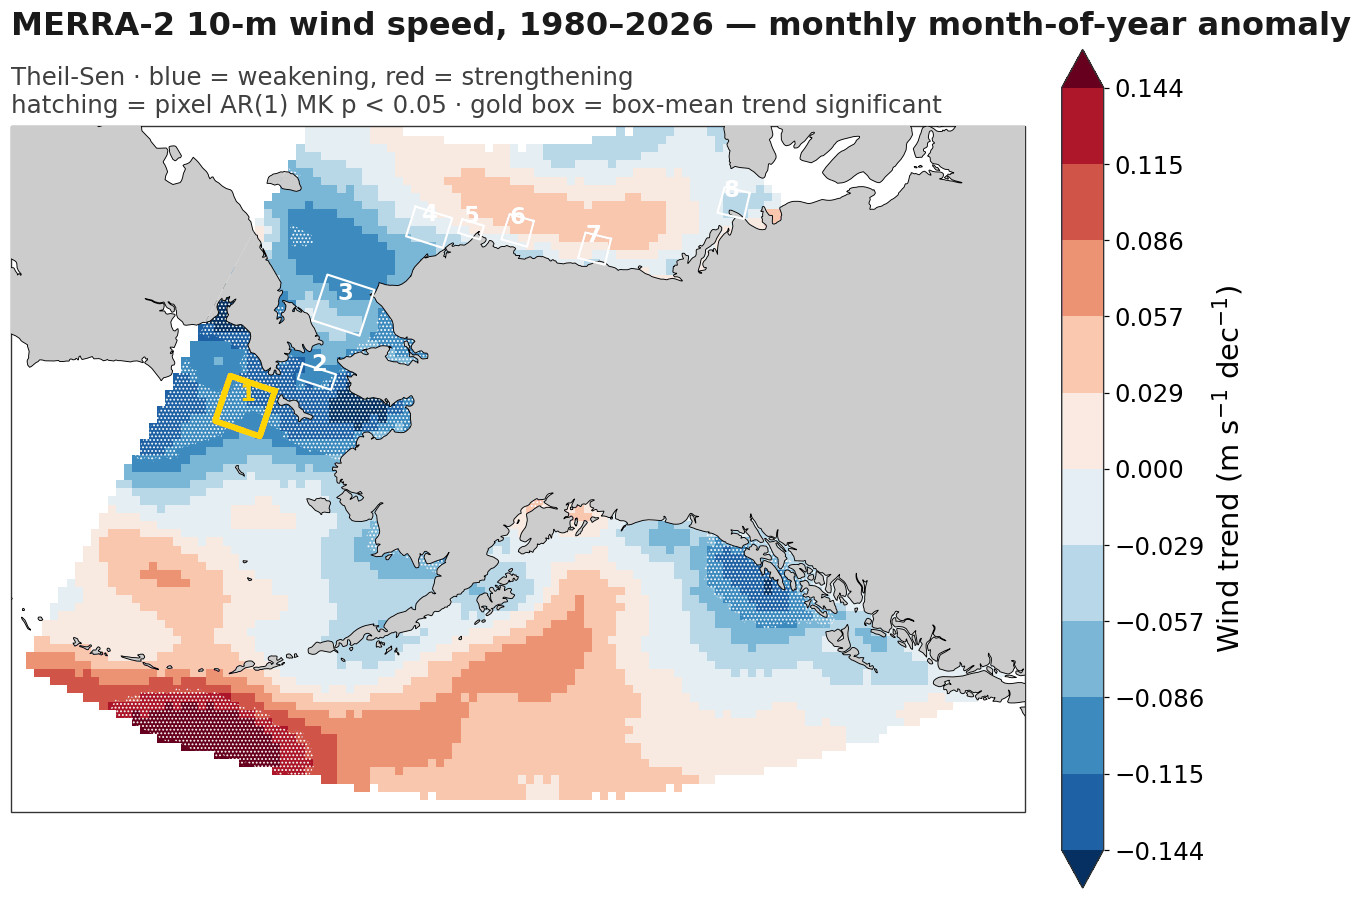

speed: median -0.012 m/s/dec | 61% of fit pixels weakening | 19% with p < 0.05


In [11]:
spd_slope, spd_p = pixel_trend_abs(SUB["spd"])
spd_box = box_trend_abs("spd")

tbl_spd = pd.DataFrame(spd_box).T.rename(columns={"per_dec": "m/s per decade", "p": "p_AR1",
                                                  "n": "n_months"})
tbl_spd["sig"] = [_stars(p) for p in tbl_spd["p_AR1"]]
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
print("box-mean wind-speed trend (Theil-Sen on the monthly anomaly):\n"); print(tbl_spd)

vmax   = max(float(np.nanpercentile(np.abs(spd_slope), 98)), 0.05)
levels = np.round(np.linspace(-vmax, vmax, 11), 3)
cmap   = DIVCMAP.copy(); cmap.set_bad("#dddddd", 0.0)
norm_t = mcolors.BoundaryNorm(levels, cmap.N, extend="both")
X, Y   = np.meshgrid(xs, ys)

# hatch colour is scoped per figure: white reads over this dark ramp
with plt.rc_context({"hatch.color": "white", "hatch.linewidth": 0.8}):
    fig = plt.figure(figsize=(14.5, 11)); ax = plt.axes(projection=disp)
    im = ax.imshow(spd_slope, origin="upper", extent=[x0, x1, y0, y1], transform=data_crs,
                   norm=norm_t, cmap=cmap, interpolation="nearest", zorder=1)
    s = np.where(np.isfinite(spd_p) & (spd_p < SIG), 1.0, np.nan)
    ax.contourf(X, Y, s, levels=[0.5, 1.5], colors="none", hatches=["....."],
                transform=data_crs, zorder=4)
    base_map(ax)
    draw_boxes(ax, sig={n: (np.isfinite(r["p"]) and r["p"] < SIG) for n, r in spd_box.items()})
    cb = fig.colorbar(im, ax=ax, shrink=0.9, ticks=levels, extend="both", pad=0.03)
    style_cbar(cb, "Wind trend (m s$^{-1}$ dec$^{-1}$)")
    map_title(ax, f"MERRA-2 10-m wind speed, {WT[0]:%Y}–{WT[-1]:%Y} — monthly month-of-year anomaly",
              f"Theil-Sen · blue = weakening, red = strengthening\n"
              f"hatching = pixel AR(1) MK p < {SIG:g} · gold box = box-mean trend significant")
    save_fig(fig, "wind_speed_trend_monthly_anom")
    plt.show()

_f = np.isfinite(spd_slope)
print(f"speed: median {np.nanmedian(spd_slope):+.3f} m/s/dec | "
      f"{100*np.nanmean(spd_slope[_f] < 0):.0f}% of fit pixels weakening | "
      f"{100*np.nanmean(np.isfinite(spd_p[_f]) & (spd_p[_f] < SIG)):.0f}% with p < {SIG}")

## 8. Figure 2 — **directional** change

Direction is mapped through the components, not through a bearing: a Theil-Sen fit on a compass angle
is meaningless because of the wrap-around at 0°/360°. Panels **a** and **b** trend the zonal and
meridional anomalies separately; panel **c** compares the mean wind vector of the first decade with
that of the last, which is a two-vector comparison and so also wrap-around-safe. Rotation is left
undefined (grey) where either decade's mean vector is shorter than 0.5 m s⁻¹, since an angle between
near-zero vectors is noise.

Arrows point the direction the wind blows **toward**.

   fit 20,568/30,758 strided pixels in 2.0 min
   fit 20,568/30,758 strided pixels in 2.0 min
box-mean component trends and rotation of the mean wind vector:

      u m/s/dec   p_u sig_u  v m/s/dec   p_v sig_v  dir_first_decade  \
box                                                                    
DBO1      0.101 0.051    ns      0.086 0.168    ns           225.613   
DBO2      0.142 0.000   ***      0.055 0.456    ns           213.056   
DBO3      0.146 0.002    **      0.038 0.600    ns           214.170   
DBO4      0.044 0.626    ns      0.010 0.840    ns           254.778   
DBO5      0.001 0.992    ns      0.047 0.226    ns           254.788   
DBO6     -0.075 0.382    ns      0.106 0.003    **           248.307   
DBO7     -0.028 0.770    ns      0.012 0.517    ns           252.976   
DBO8      0.054 0.383    ns      0.007 0.809    ns           241.623   

      dir_last_decade  rotation_deg  
box                                  
DBO1          227.081         1.469  
DBO2  

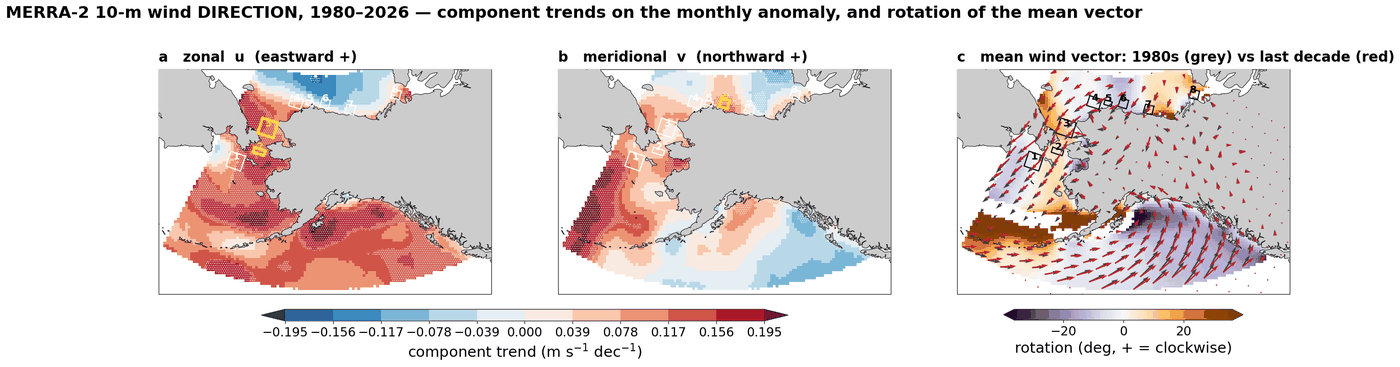

In [12]:
u_slope, u_p = pixel_trend_abs(SUB["u"])
v_slope, v_p = pixel_trend_abs(SUB["v"])

# signed angle from the early to the late mean vector, degrees, +ve = clockwise
dtheta = np.degrees(np.arctan2(u0*v1 - v0*u1, u0*u1 + v0*v1))
_weak = (np.hypot(u0, v0) < 0.5) | (np.hypot(u1, v1) < 0.5)
dtheta[_weak] = np.nan

box_u, box_v = box_trend_abs("u"), box_trend_abs("v")
rows = []
for n, m in box_masks.items():
    a0 = np.arctan2(np.nanmean(u0[m]), np.nanmean(v0[m]))
    a1 = np.arctan2(np.nanmean(u1[m]), np.nanmean(v1[m]))
    rot = np.degrees(np.arctan2(np.sin(a1 - a0), np.cos(a1 - a0)))
    rows.append((n, box_u[n]["per_dec"], box_u[n]["p"], _stars(box_u[n]["p"]),
                 box_v[n]["per_dec"], box_v[n]["p"], _stars(box_v[n]["p"]),
                 np.degrees(a0) % 360, np.degrees(a1) % 360, rot))
tbl_dir = pd.DataFrame(rows, columns=["box", "u m/s/dec", "p_u", "sig_u", "v m/s/dec", "p_v",
                                      "sig_v", "dir_first_decade", "dir_last_decade",
                                      "rotation_deg"]).set_index("box")
print("box-mean component trends and rotation of the mean wind vector:\n"); print(tbl_dir)
print("\ndirections are the bearing the wind blows TOWARD, deg clockwise from north; "
      "rotation is first -> last decade, +ve = clockwise.")

# height is set to what three aspect-locked maps + horizontal colorbars actually need; a taller
# canvas just pads the figure with whitespace because GeoAxes cannot stretch to fill it
fig, axes = plt.subplots(1, 3, figsize=(26, 7.0), subplot_kw={"projection": disp})
_all = np.concatenate([u_slope[np.isfinite(u_slope)], v_slope[np.isfinite(v_slope)]])
cmax = max(float(np.nanpercentile(np.abs(_all), 98)), 0.05)
lv = np.round(np.linspace(-cmax, cmax, 11), 3)
cm = DIVCMAP.copy(); cm.set_bad("#dddddd", 0.0)
nm = mcolors.BoundaryNorm(lv, cm.N, extend="both")
X, Y = np.meshgrid(xs, ys)

with plt.rc_context({"hatch.color": "white", "hatch.linewidth": 0.8}):
    for ax, (fld, pv, lab, bx) in zip(
            axes[:2],
            [(u_slope, u_p, "a   zonal  u  (eastward +)", box_u),
             (v_slope, v_p, "b   meridional  v  (northward +)", box_v)]):
        im = ax.imshow(fld, origin="upper", extent=[x0, x1, y0, y1], transform=data_crs,
                       norm=nm, cmap=cm, interpolation="nearest", zorder=1)
        s = np.where(np.isfinite(pv) & (pv < SIG), 1.0, np.nan)
        ax.contourf(X, Y, s, levels=[0.5, 1.5], colors="none", hatches=["....."],
                    transform=data_crs, zorder=4)
        base_map(ax)
        draw_boxes(ax, sig={n: (np.isfinite(r["p"]) and r["p"] < SIG) for n, r in bx.items()},
                   fs=FS_BOX - 2)
        ax.text(0.0, 1.02, lab, transform=ax.transAxes, ha="left", va="bottom",
                fontsize=FS_TITLE - 3, fontweight="bold")
    cb = fig.colorbar(im, ax=axes[:2].tolist(), shrink=0.72, ticks=lv, extend="both",
                      orientation="horizontal", pad=0.05, aspect=45)
    style_cbar(cb, "component trend (m s$^{-1}$ dec$^{-1}$)")

ax = axes[2]
rmax = float(np.nanpercentile(np.abs(dtheta[np.isfinite(dtheta)]), 95)) or 30.0
im2 = ax.imshow(dtheta, origin="upper", extent=[x0, x1, y0, y1], transform=data_crs,
                cmap="PuOr_r", vmin=-rmax, vmax=rmax, interpolation="nearest", zorder=1)
base_map(ax); draw_boxes(ax, base_color="black", fs=FS_BOX - 2)
Q = 45                                              # quiver subsample on the 4 km grid
lo2, la2 = lons2d[::Q, ::Q], lats2d[::Q, ::Q]
for uu, vv, col in [(u0, v0, "0.25"), (u1, v1, "#c1272d")]:
    ax.quiver(lo2, la2, uu[::Q, ::Q], vv[::Q, ::Q], transform=ccrs.PlateCarree(),
              color=col, scale=60, width=0.004, zorder=8)
ax.text(0.0, 1.02, f"c   mean wind vector: {WT.year.min()}s (grey) vs last decade (red)",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=FS_TITLE - 3, fontweight="bold")
cb2 = fig.colorbar(im2, ax=ax, shrink=0.72, extend="both", orientation="horizontal",
                   pad=0.05, aspect=22)
style_cbar(cb2, "rotation (deg, + = clockwise)")

fig.suptitle(f"MERRA-2 10-m wind DIRECTION, {WT[0]:%Y}–{WT[-1]:%Y} — component trends on the "
             f"monthly anomaly, and rotation of the mean vector",
             fontsize=FS_TITLE, x=0.02, ha="left", fontweight="bold", y=1.0)
save_fig(fig, "wind_direction_components_rotation")
plt.show()

## 9. Write the box tables

In [13]:
tbl_spd.to_csv(OUT_DIR / "wind_speed_box_trends_monthly_anom.csv")
tbl_dir.to_csv(OUT_DIR / "wind_direction_box_trends.csv")
print("wrote:")
for p in sorted(OUT_DIR.glob("wind_*")):
    print("  ", p.name)
print("\nCompare the speed column against the DBO scorecard's 'Wind speed (10 m)' row: same "
      "estimator, same series, same boxes, so they should now agree.")

wrote:
   wind_direction_box_trends.csv
   wind_direction_components_rotation.pdf
   wind_direction_components_rotation.png
   wind_speed_box_trends_monthly_anom.csv
   wind_speed_trend_monthly_anom.pdf
   wind_speed_trend_monthly_anom.png

Compare the speed column against the DBO scorecard's 'Wind speed (10 m)' row: same estimator, same series, same boxes, so they should now agree.
